# MRSIPrep walkthrough: one subject, stage by stage

This notebook walks through MRSIPrep's processing pipeline one stage at a time, using a single subject (`sub-01`) from the public **SynthMRSI-Project** validation dataset (Zenodo, [doi:10.5281/zenodo.21477047](https://doi.org/10.5281/zenodo.21477047), CC0).

**The outputs below are already rendered from a real run** (all stages ran live, via the Docker-based launch described in `README.md`, including the ANTs registration, PETPVC partial-volume correction, and connectivity-matrix stages) — you can read the figures and tables directly without executing anything. To reproduce them yourself or run on a different subject, see "Requires" below.

**This notebook calls MRSIPrep's own code, not a reimplementation.** Each stage below imports and runs the real function MRSIPrep's pipeline calls internally (`mrsiprep.mrsi.filtering.filter_metabolite_maps`, `mrsiprep.registration.mrsi_to_t1.run_mrsi_to_t1`, `mrsiprep.mrsi.pvc.run_pvc`, `mrsiprep.parcellation.extraction.extract_regional_metabolites`, `mrsiprep.connectivity.connectivity.compute_metabolite_connectivity`, `mrsiprep.reports.html.generate_subject_report`), writing its output to a scratch directory and loading the result back with `mrsiprep.reports.slices`'s own plotting helpers — the same ones the HTML QC report uses.

**Requires:** the `mrsiprep` package importable (`pip install -e .` from the repo root, or any environment with its Python dependencies), plus network access on first run (`templateflow` downloads the MNI template once, then caches it). Re-running every stage live, including registration and partial-volume correction with their real default backends (ANTs, PETPVC), needs those binaries on `PATH` — see `README.md` for a tested Docker-based launch command that provides them, or run with a plain `pip install` and let the registration/PVC cells fall back to this subject's already-computed result (stated explicitly when that happens).

**On binaries.** Two stages shell out to external tools MRSIPrep bundles into its Docker image: MRSI-to-T1w registration's default backend uses ANTs (`antsRegistrationSyN.sh`), and partial-volume correction uses PETPVC (`petpvc`). If either isn't on `PATH` in the environment running this notebook, that cell falls back to loading the dataset's own already-computed result (produced by the real pipeline, just not re-run live here) and says so explicitly — it never silently substitutes synthetic output. The notebook's registration cell uses the FSL FLIRT backend instead where available, since that one *can* run without ANTs installed.

**About the data.** SynthMRSI-Project pairs real T1-weighted anatomical images (from two CC0 OpenNeuro datasets) with *model-synthesized* MRSI metabolite signal (a 3D U-Net; see the MRSIPrep manuscript, Validation Datasets section). No real MRSI acquisition underlies these numbers — this is example/test data, not a clinical reference. This subject was processed without `--parcellation-mode chimera`; this notebook's connectivity stage instead uses a pre-bundled **MNI-space atlas** warped into subject space (`--parcellation-mode atlas --atlas chimera-LFMIHIFIS_scale3`), which needs no FreeSurfer `recon-all` — see Stage 7 for what this distinction means.

**To view this notebook:** download it and open it locally (JupyterLab, VS Code, or `jupyter nbconvert --to html`). GitHub's own `.ipynb` viewer does not reliably render matplotlib figures embedded at this size — if you're reading this on github.com and don't see images below, that's why.

In [1]:
%matplotlib inline

import shutil
import sys
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
import pandas as pd

# If mrsiprep isn't pip-installed, fall back to a repo checkout next to this
# notebook's parent (docs/notebooks/../../ == the repo root).
try:
    import mrsiprep  # noqa: F401
except ImportError:
    sys.path.insert(0, str(Path.cwd().resolve().parent.parent))

from mrsiprep.config.settings import MRSIPrepConfig
from mrsiprep.reports.slices import load_canonical_data, triplanar_slices, axial_slices_center_weighted

# Point this at a local copy of SynthMRSI-Project
# (https://doi.org/10.5281/zenodo.21477047).
DATASET_ROOT = Path("SynthMRSI-Project")
MRSINMRS_FILE = None  # Or Path("/path/to/mrsinmrs.json") to override the default
SUBJECT, SESSION = "01", "01"
METABOLITES = ["NAANAAG", "GPCPCh", "CrPCr", "GluGln", "Ins"]
MET = "CrPCr"  # the reference metabolite (--ref-met) used for this recording

# This subject's already-computed derivatives, as a fallback source whenever
# a stage can't be run live in this environment (no ANTs/PETPVC on PATH).
PRECOMPUTED = DATASET_ROOT / "derivatives" / "mrsiprep" / f"sub-{SUBJECT}" / f"ses-{SESSION}"
RAW_MRSI_ROOT = DATASET_ROOT / "derivatives" / "mrsi-orig" / f"sub-{SUBJECT}" / f"ses-{SESSION}"

# Everything this notebook computes live is written here, not into the
# dataset itself.
SCRATCH_DIR = Path(tempfile.mkdtemp(prefix="mrsiprep_walkthrough_"))
print(f"Live-computed outputs will be written under: {SCRATCH_DIR}")

config = MRSIPrepConfig(
    bids_dir=DATASET_ROOT,
    mrsinmrs_file=MRSINMRS_FILE,
    output_dir=SCRATCH_DIR,
    analysis_level="participant",
    metabolites=METABOLITES,
    ref_met=MET,
    atlas="chimera-LFMIHIFIS_scale3",
)
config.require_mrsinmrs()


def mid_axial(volume: np.ndarray, index: int | None = None) -> np.ndarray:
    slices = triplanar_slices(volume, center_ijk=None if index is None else (volume.shape[0] // 2, volume.shape[1] // 2, index))
    return slices["axial"]


def show(ax, slice_2d, title, cmap="viridis", vmax=None):
    ax.imshow(slice_2d, cmap=cmap, vmax=vmax)
    ax.set_title(title, fontsize=10)
    ax.axis("off")


def show_axial_grid(volume: np.ndarray, title: str, n_slices: int = 10, cmap: str = "viridis", vmax=None, overlay: np.ndarray | None = None, overlay_cmap: str = "magma", overlay_alpha: float = 0.5, colorbar_label: str | None = None):
    """Same slice-selection convention as the real QC report's MRSI-Raw and
    registration-alignment tabs (mrsiprep.reports.slices.axial_slices_center_weighted,
    N_SLICES=10): a row of axial slices spanning the volume, denser near the
    center where real MRSI-slab coverage concentrates. The background/overlay
    colormap and alpha also match the report's own static compositing
    convention (mrsiprep/reports/slices.py: render_triplanar_png /
    render_multi_slice_triplanar_png -- cmap="gray" background, "magma"
    overlay at alpha=0.5), just without that function's flicker-SVG toggle.

    With no overlay, colorbar_label (if given) labels the background image
    itself instead -- for panels showing a single quantity on its own grid
    (e.g. Stage 6's MNI-space metabolite map) rather than one map overlaid
    on another."""
    slices = axial_slices_center_weighted(volume, n_slices)
    fig, axes = plt.subplots(1, len(slices), figsize=(1.8 * len(slices), 2.4))
    if len(slices) == 1:
        axes = [axes]
    background_im = overlay_im = None
    for ax, (index, plane) in zip(axes, slices):
        background_im = ax.imshow(plane, cmap=cmap, vmax=vmax)
        if overlay is not None:
            overlay_slices = dict(axial_slices_center_weighted(overlay, n_slices))
            if index in overlay_slices:
                overlay_plane = overlay_slices[index]
                masked = np.ma.masked_where(overlay_plane <= 0, overlay_plane)
                overlay_im = ax.imshow(masked, cmap=overlay_cmap, alpha=overlay_alpha, vmax=vmax)
        ax.set_title(f"z={index}", fontsize=8)
        ax.axis("off")
    colorbar_im = overlay_im if overlay_im is not None else background_im
    if colorbar_im is not None and colorbar_label is not None:
        fig.colorbar(colorbar_im, ax=axes, fraction=0.025, pad=0.02, label=colorbar_label)
    fig.suptitle(title)
    plt.show()

Live-computed outputs will be written under: /tmp/mrsiprep_walkthrough_kx35my4z


## Stage 0 — Raw input

MRSIPrep's input is a T1-weighted anatomical and already-quantified MRSI metabolite maps (signal + quality metrics: CRLB, SNR, linewidth/FWHM). Nothing has been processed yet: the MRSI signal map is still on its own native acquisition grid, far coarser than the T1w, and T1w/MRSI are not yet aligned.

The required `derivatives/mrsi-orig/mrsinmrs.json` file (or the custom file selected with `MRSINMRS_FILE`, shown below) documents the acquisition protocol following the MRSinMRS minimum-reporting-standard consensus — MRSIPrep surfaces it directly in the QC report so a study's acquisition provenance travels with its processing provenance.

T1w grid:  (160, 192, 192)
MRSI grid: (32, 42, 22)  (coarser native resolution -- these are not yet aligned)


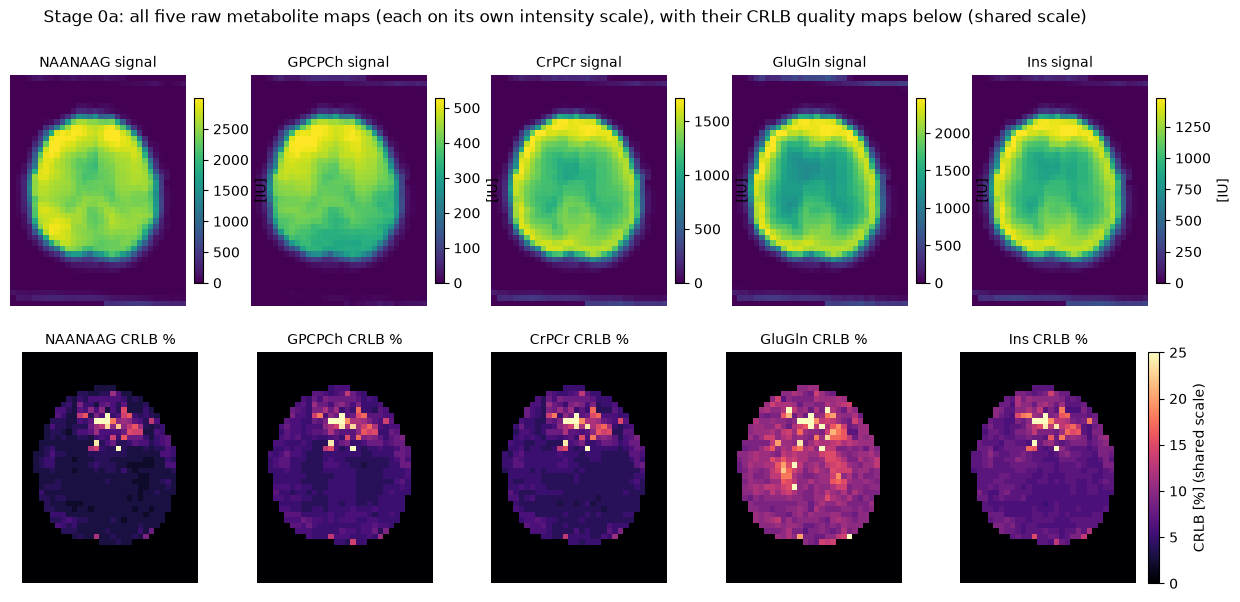

In [2]:
raw_t1w_path = DATASET_ROOT / f"sub-{SUBJECT}" / f"ses-{SESSION}" / "anat" / f"sub-{SUBJECT}_ses-{SESSION}_acq-mprage_T1w.nii.gz"
raw_t1w = load_canonical_data(raw_t1w_path)

raw_mrsi_signal_paths = {met: RAW_MRSI_ROOT / f"sub-{SUBJECT}_ses-{SESSION}_space-orig_met-{met}_desc-signal_mrsi.nii.gz" for met in METABOLITES}
raw_mrsi_crlb_paths = {met: RAW_MRSI_ROOT / f"sub-{SUBJECT}_ses-{SESSION}_space-orig_met-{met}_desc-crlb_mrsi.nii.gz" for met in METABOLITES}
raw_mrsi_signal = {met: load_canonical_data(p) for met, p in raw_mrsi_signal_paths.items()}
raw_mrsi_crlb = {met: load_canonical_data(p) for met, p in raw_mrsi_crlb_paths.items()}

# Shared display scale for the reference metabolite (MET), reused by every
# later stage that shows MET on its own native-range color scale.
vmax = float(np.percentile(raw_mrsi_signal[MET][raw_mrsi_signal[MET] > 0], 99)) if np.any(raw_mrsi_signal[MET] > 0) else None

print(f"T1w grid:  {raw_t1w.shape}")
print(f"MRSI grid: {raw_mrsi_signal[MET].shape}  (coarser native resolution -- these are not yet aligned)")

mid_z = raw_mrsi_signal[MET].shape[2] // 2
signal_slices = {met: mid_axial(raw_mrsi_signal[met], mid_z) for met in METABOLITES}
crlb_slices = {met: mid_axial(raw_mrsi_crlb[met], mid_z) for met in METABOLITES}

# CRLB (a %, directly comparable across metabolites) shares one vmax and one
# colorbar -- computed from the displayed slice, not the whole volume, so a
# rare sentinel voxel elsewhere (e.g. CRLB=999, a "fit failed" marker) can't
# skew it. Signal, by contrast, is NOT comparable across metabolites (each
# lives on its own native intensity scale -- GPCPCh's raw signal here is
# roughly 5x smaller than NAANAAG's), so each signal panel gets its own
# vmax and its own colorbar instead of one shared scale that would crush
# the smaller-signal metabolites to a uniform blob.
all_crlb_slice_vals = np.concatenate([s[s > 0] for s in crlb_slices.values()])
vmax_crlb_row = float(np.percentile(all_crlb_slice_vals, 99)) if all_crlb_slice_vals.size else None

fig, axes = plt.subplots(2, len(METABOLITES), figsize=(3 * len(METABOLITES), 6.6))
crlb_im = None
for col, met in enumerate(METABOLITES):
    signal_plane = signal_slices[met]
    vmax_met = float(np.percentile(signal_plane[signal_plane > 0], 99)) if np.any(signal_plane > 0) else None
    signal_im = axes[0, col].imshow(signal_plane, cmap="viridis", vmax=vmax_met)
    axes[0, col].set_title(f"{met} signal", fontsize=10)
    axes[0, col].axis("off")
    fig.colorbar(signal_im, ax=axes[0, col], fraction=0.046, pad=0.04, label="[IU]")
    crlb_im = axes[1, col].imshow(crlb_slices[met], cmap="magma", vmax=vmax_crlb_row)
    axes[1, col].set_title(f"{met} CRLB %", fontsize=10)
    axes[1, col].axis("off")
fig.colorbar(crlb_im, ax=axes[1, :], fraction=0.015, pad=0.01, label="CRLB [%] (shared scale)")
fig.suptitle("Stage 0a: all five raw metabolite maps (each on its own intensity scale), with their CRLB quality maps below (shared scale)")
plt.show()

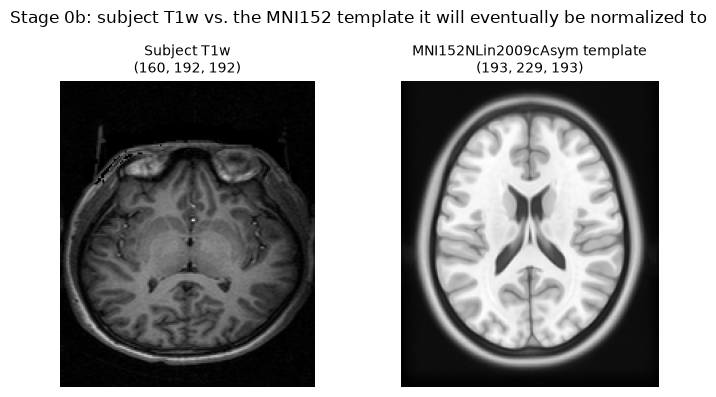

In [3]:
from mrsiprep.config.templates import template_head

# Downloads once via templateflow, then caches locally (needs network the
# first time this cell runs in a fresh environment).
template_img = template_head(resolution_mm=1)
template_data = np.asarray(nib.as_closest_canonical(template_img).get_fdata())

fig, axes = plt.subplots(1, 2, figsize=(7, 4))
show(axes[0], mid_axial(raw_t1w), f"Subject T1w\n{raw_t1w.shape}", cmap="gray")
show(axes[1], mid_axial(template_data), f"MNI152NLin2009cAsym template\n{template_data.shape}", cmap="gray")
fig.suptitle("Stage 0b: subject T1w vs. the MNI152 template it will eventually be normalized to")
plt.tight_layout()
plt.show()

In [4]:
from mrsiprep.io.mrsinmrs import resolve_mrsinmrs

parsed_mrsinmrs = config.mrsinmrs
resolved_mrsinmrs = resolve_mrsinmrs(parsed_mrsinmrs, SUBJECT, SESSION)
mrsinmrs_table = pd.DataFrame(sorted(resolved_mrsinmrs.items()), columns=["Field", "Value"])
mrsinmrs_table

,Field,Value
0,AcquisitionDurationMS,389
1,Averages,1
2,AveragingMode,N.A.
3,CoilElements,N.A. (synthetic)
4,CombinedMetabolites,"tNAA (NAA+NAAG), tCr (Cr+PCr), Cho (GPC+PCh), ..."
5,CompressedSensingAccelerationFactor,N.A. (synthetic)
6,DataProcessing,Model-synthesized signal (3D U-Net trained on ...
7,DeltaFrequencyPPM,0.0
8,Dimension,3D
9,FIDPointsVectorSize,512


## Stage 1 — Spike filtering (live)

Calls `mrsiprep.mrsi.filtering.filter_metabolite_maps` directly — the exact function the pipeline's MRSI track calls. This is pure Python/SciPy (median filtering + biharmonic inpainting), so it runs live here with no external binary required. Needs a brain mask; we use this subject's own already-computed one (the mask itself comes from the anatomical track, run separately, see Stage 2).

Each metabolite below is shown at its *own* best slice: the axial slice carrying the most of *that* metabolite's own flagged voxels, not a single slice shared across all five (a metabolite with few flagged voxels, or voxels on a different slice than another metabolite's, would otherwise show nothing at all).

NAANAAG: 0 voxel(s) flagged and repaired.
GPCPCh: 0 voxel(s) flagged and repaired.
CrPCr: 7 voxel(s) flagged and repaired.
GluGln: 25 voxel(s) flagged and repaired.
Ins: 20 voxel(s) flagged and repaired.


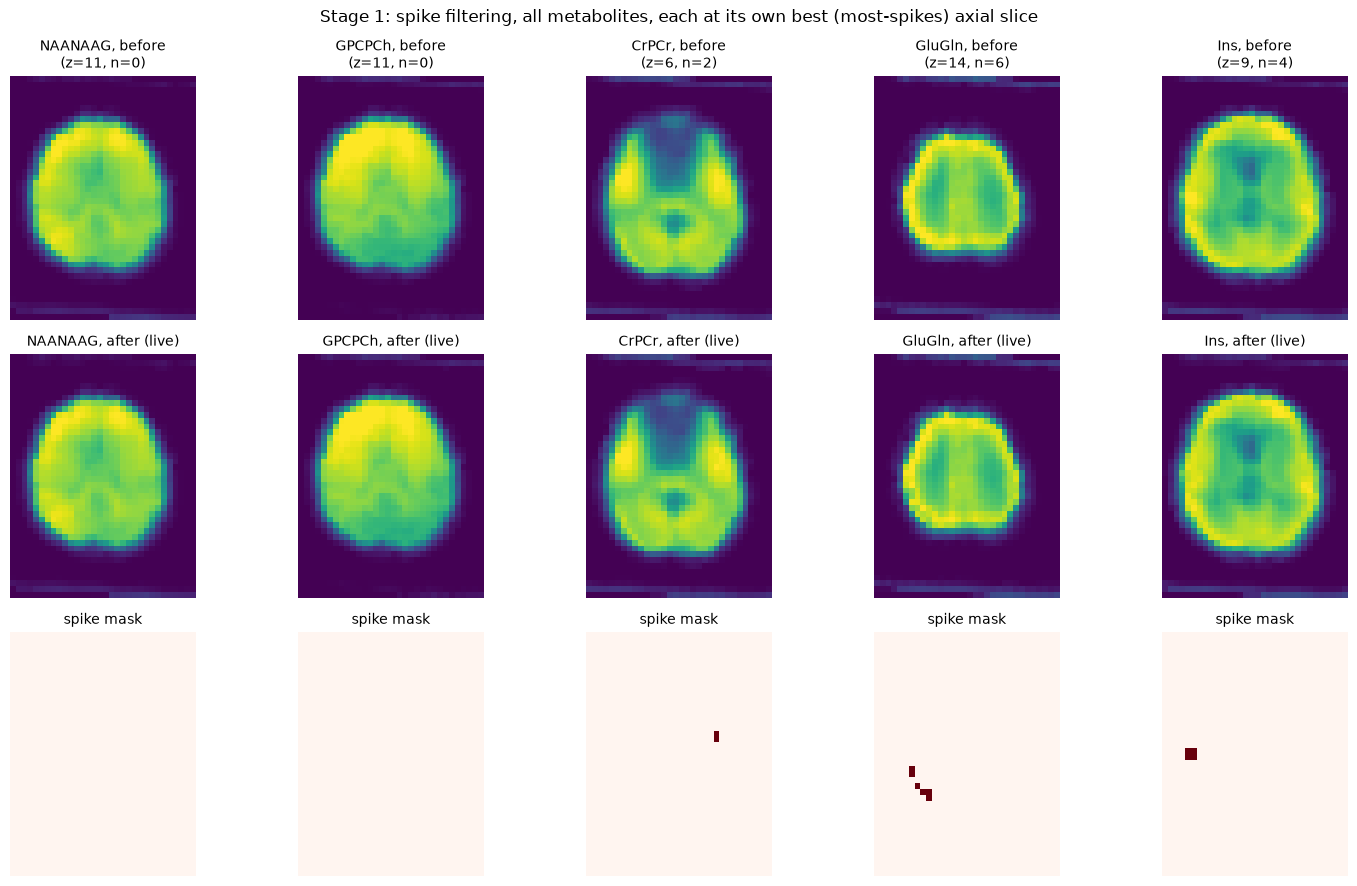

In [5]:
from mrsiprep.mrsi.filtering import filter_metabolite_maps

brainmask_path = PRECOMPUTED / "confounds" / f"sub-{SUBJECT}_ses-{SESSION}_space-mrsi_desc-brain_mask.nii.gz"
filtered_paths = filter_metabolite_maps(config, SUBJECT, SESSION, raw_mrsi_signal_paths, brainmask_path)

post_spike = {met: load_canonical_data(filtered_paths[met]) for met in METABOLITES}
spike_mask_paths = {
    met: filtered_paths[met].parent.parent.parent / "confounds" / f"sub-{SUBJECT}_ses-{SESSION}_space-mrsi_met-{met}_desc-spikemask_mask.nii.gz"
    for met in METABOLITES
}
spike_masks = {met: load_canonical_data(p) for met, p in spike_mask_paths.items()}

flagged_counts = {met: int(np.sum(mask > 0)) for met, mask in spike_masks.items()}
for met, n in flagged_counts.items():
    print(f"{met}: {n} voxel(s) flagged and repaired.")

# Per-metabolite best slice: the axial slice carrying the most of THIS
# metabolite's own flagged voxels (falling back to the mid-slice for a
# metabolite with none flagged at all, e.g. NAANAAG/GPCPCh here).
best_slice_per_met = {}
for met in METABOLITES:
    per_slice_counts = spike_masks[met].sum(axis=(0, 1))
    if per_slice_counts.max() > 0:
        best_slice_per_met[met] = int(np.argmax(per_slice_counts))
    else:
        best_slice_per_met[met] = spike_masks[met].shape[2] // 2

fig, axes = plt.subplots(3, len(METABOLITES), figsize=(3 * len(METABOLITES), 9))
for col, met in enumerate(METABOLITES):
    slice_index = best_slice_per_met[met]
    n_here = int(spike_masks[met][:, :, slice_index].sum())
    vmax_met = float(np.percentile(raw_mrsi_signal[met][raw_mrsi_signal[met] > 0], 99)) if np.any(raw_mrsi_signal[met] > 0) else None
    show(axes[0, col], mid_axial(raw_mrsi_signal[met], slice_index), f"{met}, before\n(z={slice_index}, n={n_here})", vmax=vmax_met)
    show(axes[1, col], mid_axial(post_spike[met], slice_index), f"{met}, after (live)", vmax=vmax_met)
    show(axes[2, col], mid_axial(spike_masks[met], slice_index), "spike mask", cmap="Reds")
fig.suptitle("Stage 1: spike filtering, all metabolites, each at its own best (most-spikes) axial slice")
plt.tight_layout()
plt.show()

## Stage 2 — Anatomical segmentation

In parallel with the MRSI track, the anatomical track skull-strips the T1w image and runs SynthSeg for brain/tissue segmentation, producing GM/WM/CSF probability maps alongside the brain mask and region labels. SynthSeg is a deep-learning model with its own multi-gigabyte weights and a non-trivial runtime per subject, so rather than re-running it live, this cell loads this subject's already-computed segmentation — the output of `mrsiprep.workflows.steps`' anatomical step, run once for this dataset.

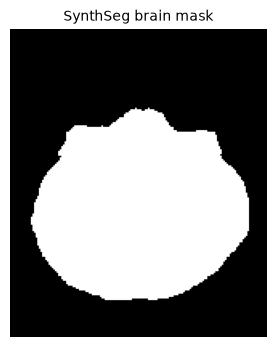

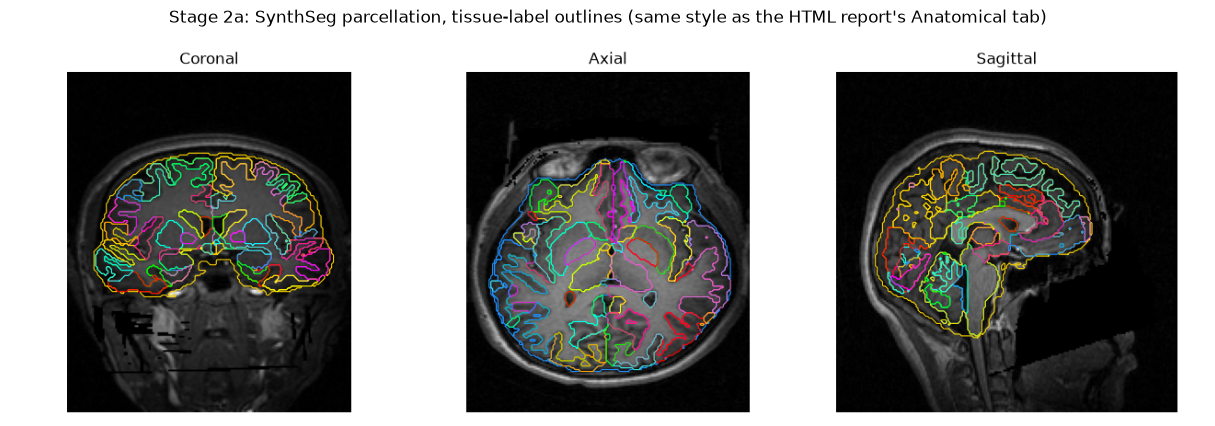

In [6]:
t1w_brain_mask_path = PRECOMPUTED / "anat" / "synthseg" / f"sub-{SUBJECT}_ses-{SESSION}_space-T1w_desc-synthsegBrain_mask.nii.gz"
t1w_parc_path = PRECOMPUTED / "anat" / "synthseg" / f"sub-{SUBJECT}_ses-{SESSION}_space-T1w_desc-synthsegParcRobust_dseg.nii.gz"
t1w_brain_path = PRECOMPUTED / "anat" / "synthseg" / f"sub-{SUBJECT}_ses-{SESSION}_space-T1w_desc-synthsegBrain_T1w.nii.gz"

t1w_brain_mask = load_canonical_data(t1w_brain_mask_path)
t1w_parc = load_canonical_data(t1w_parc_path)

show(plt.subplots(figsize=(4, 4))[1], mid_axial(t1w_brain_mask), "SynthSeg brain mask", cmap="gray")
plt.show()

# Same triplanar tissue-label-outline rendering the real report's
# "Anatomical" tab uses (mrsiprep/reports/tissue.py -> render_triplanar_png
# with mode="outline"): coronal/axial/sagittal at the true mid-volume slice
# (triplanar_slices with no center_ijk override), so more real anatomical
# structure is visible than a single arbitrary axial slice.
from mrsiprep.reports.slices import render_triplanar_png
import matplotlib.image as mpimg

t1w_slices = triplanar_slices(raw_t1w)
parc_slices = triplanar_slices(t1w_parc)
outline_png = SCRATCH_DIR / "stage2a_tissue_outlines.png"
render_triplanar_png(t1w_slices, outline_png, overlay_slices=parc_slices, mode="outline")
fig, ax = plt.subplots(figsize=(13, 4.3))
ax.imshow(mpimg.imread(outline_png))
ax.axis("off")
fig.suptitle("Stage 2a: SynthSeg parcellation, tissue-label outlines (same style as the HTML report's Anatomical tab)")
plt.tight_layout()
plt.show()

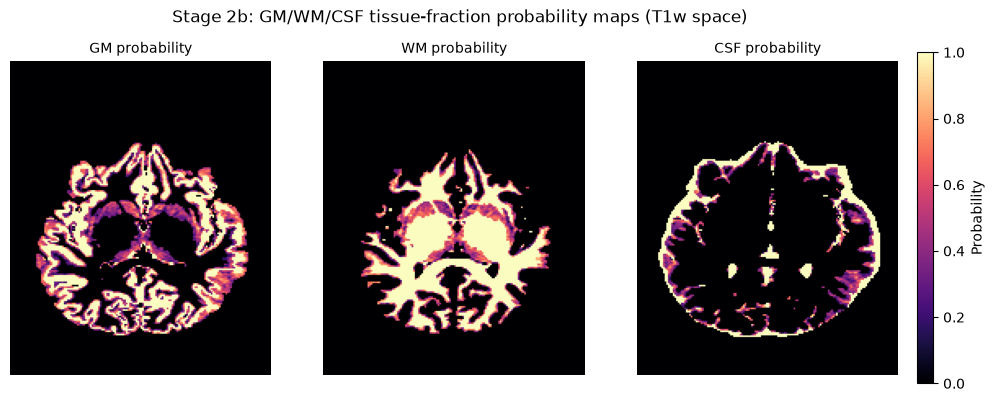

In [7]:
tissue_t1w_paths = {label: PRECOMPUTED / "confounds" / f"sub-{SUBJECT}_ses-{SESSION}_space-T1w_label-{label}_probseg.nii.gz" for label in ("GM", "WM", "CSF")}
tissue_t1w = {label: load_canonical_data(p) for label, p in tissue_t1w_paths.items()}

# Same colormap the real HTML report uses for all three tissue maps
# (mrsiprep/reports/tissue.py -> render_triplanar_png's overlay_cmap
# default, "magma") -- there is no per-tissue color distinction in the
# report; GM/WM/CSF all share one colormap.
fig, axes = plt.subplots(1, 3, figsize=(12, 4.3))
tissue_im = None
for ax, (label, data) in zip(axes, tissue_t1w.items()):
    tissue_im = ax.imshow(mid_axial(data), cmap="magma", vmin=0, vmax=1.0)
    ax.set_title(f"{label} probability", fontsize=10)
    ax.axis("off")
fig.colorbar(tissue_im, ax=axes, fraction=0.025, pad=0.02, label="Probability")
fig.suptitle("Stage 2b: GM/WM/CSF tissue-fraction probability maps (T1w space)")
plt.show()

## Stage 3 — MRSI-to-T1w registration (live where possible)

Calls `mrsiprep.registration.mrsi_to_t1.run_mrsi_to_t1` directly. MRSIPrep's default backend is ANTs (`antsRegistrationSyN.sh`); if that's not on `PATH` in this environment, we fall back to the FSL backend (`flirt`) instead — both are real, supported `--registration-backend` choices, just not the dataset's own default. The resulting transform is applied to resample the reference metabolite map into T1w space, using `mrsiprep.mrsi.resampling.resample_ref_met_to_t1w`.

The slice grid below uses the same selection convention as the real QC report's alignment tab (10 center-weighted axial slices), showing the resampled MRSI signal overlaid on the T1w anatomical.

Registered live using backend: ants (MRSIPrep's default)


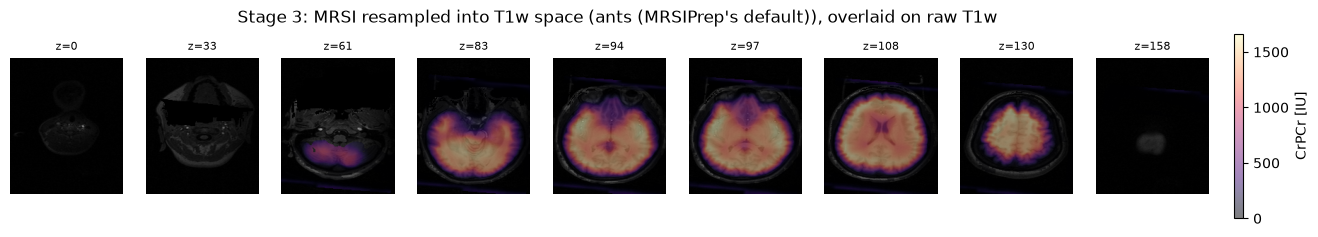

In [8]:
from mrsiprep.registration.mrsi_to_t1 import run_mrsi_to_t1
from mrsiprep.mrsi.resampling import resample_ref_met_to_t1w

mrsi_ref_path = PRECOMPUTED / "mrsi" / "orig" / f"sub-{SUBJECT}_ses-{SESSION}_space-mrsi_desc-reference_mrsi.nii.gz"

if shutil.which("antsRegistrationSyN.sh") is not None:
    reg_config = config
    backend_used = "ants (MRSIPrep's default)"
elif shutil.which("flirt") is not None:
    reg_config = MRSIPrepConfig(
        bids_dir=DATASET_ROOT, output_dir=SCRATCH_DIR, analysis_level="participant",
        mrsinmrs_file=config.mrsinmrs_file,
        metabolites=METABOLITES, ref_met=MET, registration_backend="fsl", fsl_deformable=False,
        atlas="chimera-LFMIHIFIS_scale3",
    )
    backend_used = "fsl/flirt (ANTs not found on PATH; a real, supported fallback)"
else:
    reg_config = None
    backend_used = None

if reg_config is not None:
    reg_result = run_mrsi_to_t1(reg_config, SUBJECT, SESSION, mrsi_ref_path, t1w_brain_path)
    t1w_resampled_path = resample_ref_met_to_t1w(reg_config, SUBJECT, SESSION, mrsi_ref_path, reg_result.forward, t1w_brain_path)
    t1w_resampled = load_canonical_data(t1w_resampled_path)
    print(f"Registered live using backend: {backend_used}")
else:
    reg_result = None
    t1w_resampled_path = PRECOMPUTED / "mrsi" / "orig" / f"sub-{SUBJECT}_ses-{SESSION}_space-T1w_met-{MET}_desc-signal_mrsi.nii.gz"
    t1w_resampled = load_canonical_data(t1w_resampled_path) if t1w_resampled_path.exists() else None
    print("Neither ANTs nor FSL found on PATH; registration could not run live in this environment.")

# Background is the raw T1w (not the skull-stripped one) -- matches what
# the real report's alignment tab uses (registration_overview.py's
# build_t1w_alignment_sections takes raw_t1 as its background), and the
# visible skull/scalp anatomy makes the underlying image much easier to
# see than the mostly-uniform skull-stripped brain.
show_axial_grid(raw_t1w, f"Stage 3: MRSI resampled into T1w space ({backend_used or 'not available'}), overlaid on raw T1w",
                cmap="gray", overlay=t1w_resampled, vmax=vmax, colorbar_label=f"{MET} [IU]")

## Stage 4 — Partial-volume correction (live if `petpvc` is available)

Calls `mrsiprep.mrsi.pvc.create_tissue_4d` (pure Python, stacks the GM/WM/CSF tissue-fraction maps the anatomical track already produced) and `mrsiprep.mrsi.pvc.run_pvc`, which shells out to PETPVC's RBV algorithm. `run_pvc` raises `PVCError` with a clear message if `petpvc` isn't on `PATH` — we catch exactly that and fall back to this subject's already-computed PVC output, rather than skipping the explanation.

Top row: before PVC. Bottom row: after. Same center-weighted axial slices as Stage 3, so corresponding columns are the same anatomical location.

PVC ran live via PETPVC.


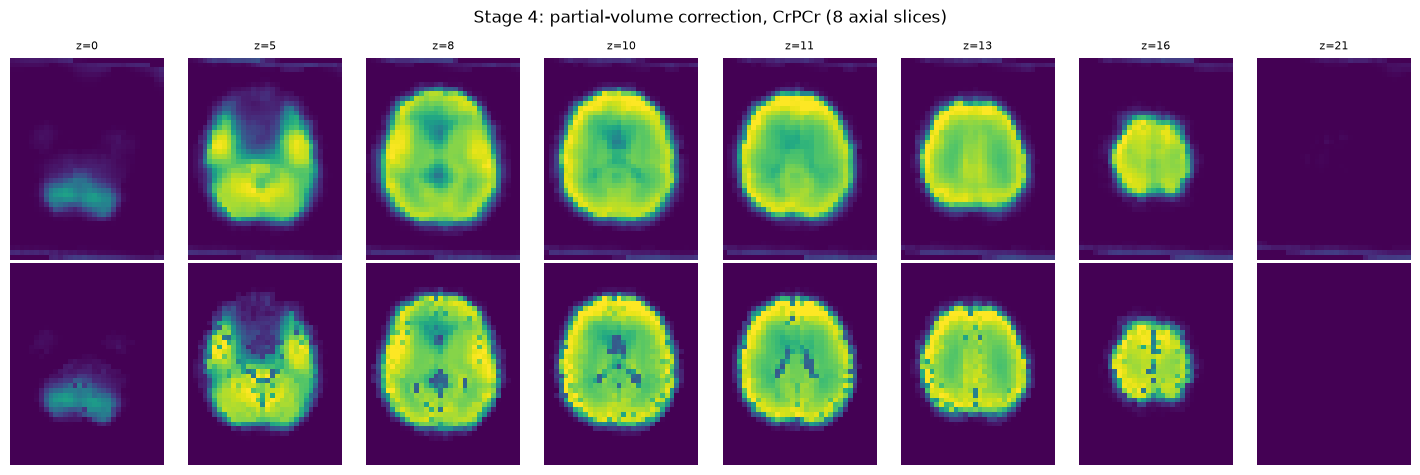

In [9]:
from mrsiprep.mrsi.pvc import create_tissue_4d, run_pvc, PVCError

tissue_mrsi_paths = {
    label: PRECOMPUTED / "confounds" / f"sub-{SUBJECT}_ses-{SESSION}_space-mrsi_label-{label}_probseg.nii.gz"
    for label in ("GM", "WM", "CSF")
}

try:
    tissue_4d_path = create_tissue_4d(config, SUBJECT, SESSION, tissue_mrsi_paths, mrsi_ref_path)
    pvc_paths = run_pvc(config, SUBJECT, SESSION, {MET: filtered_paths[MET]}, tissue_4d_path, brainmask_path, mrsi_ref_path)
    post_pvc = load_canonical_data(pvc_paths[MET])
    print("PVC ran live via PETPVC.")
except PVCError as exc:
    print(f"PVC could not run live in this environment ({exc}); showing this subject's already-computed PVC output instead.")
    post_pvc = load_canonical_data(PRECOMPUTED / "mrsi" / "orig-pvc" / f"sub-{SUBJECT}_ses-{SESSION}_space-mrsi_met-{MET}_desc-signalpvc_mrsi.nii.gz")

n_slices_pvc = 8
before_slices = axial_slices_center_weighted(post_spike[MET], n_slices_pvc)
after_slices = dict(axial_slices_center_weighted(post_pvc, n_slices_pvc))
fig, axes = plt.subplots(2, len(before_slices), figsize=(1.8 * len(before_slices), 4.8))
for col, (index, plane) in enumerate(before_slices):
    axes[0, col].imshow(plane, cmap="viridis", vmax=vmax)
    axes[0, col].set_title(f"z={index}", fontsize=8)
    axes[0, col].axis("off")
    after_plane = after_slices.get(index, np.zeros_like(plane))
    axes[1, col].imshow(after_plane, cmap="viridis", vmax=vmax)
    axes[1, col].axis("off")
axes[0, 0].set_ylabel("Before PVC", fontsize=9)
axes[1, 0].set_ylabel("After PVC", fontsize=9)
fig.suptitle(f"Stage 4: partial-volume correction, {MET} ({len(before_slices)} axial slices)")
plt.tight_layout()
plt.show()

## Stage 5 — Regional profile extraction (live)

Calls `mrsiprep.parcellation.extraction.extract_regional_metabolites` directly — pure Python, no external binary — using the SynthSeg parcellation from Stage 2 and the PVC-corrected map from Stage 4 (or its already-computed fallback) to produce a real regional-profile table, per region and per quality metric.

In [10]:
from mrsiprep.parcellation.base import ParcellationResult
from mrsiprep.parcellation.extraction import extract_regional_metabolites

mrsi_gmwm_path = PRECOMPUTED / "anat" / "synthseg" / f"sub-{SUBJECT}_ses-{SESSION}_space-mrsi_atlas-synthseg_desc-robustGMWM_dseg.nii.gz"

synthseg_parcels = ParcellationResult(
    atlas_mrsi=mrsi_gmwm_path,
    labels=PRECOMPUTED / "anat" / "synthseg" / f"sub-{SUBJECT}_ses-{SESSION}_atlas-synthseg_desc-robustGMWM.tsv",
    atlas_name="synthseg",
)
qcmask_path = PRECOMPUTED / "confounds" / f"sub-{SUBJECT}_ses-{SESSION}_space-mrsi_met-{MET}_desc-qcmask_mask.nii.gz"
snr_path = PRECOMPUTED / "confounds" / f"sub-{SUBJECT}_ses-{SESSION}_space-orig_desc-snr_mrsi.nii.gz"
linewidth_path = PRECOMPUTED / "confounds" / f"sub-{SUBJECT}_ses-{SESSION}_space-orig_desc-fwhm_mrsi.nii.gz"

# This cell's metabolite map is whichever PVC output Stage 4 produced (live
# or fallback), so the profile table reflects exactly what was shown above.
pvc_map_for_profiles = pvc_paths[MET] if "pvc_paths" in dir() else PRECOMPUTED / "mrsi" / "orig-pvc" / f"sub-{SUBJECT}_ses-{SESSION}_space-mrsi_met-{MET}_desc-signalpvc_mrsi.nii.gz"

profile_table_path = extract_regional_metabolites(
    config, SUBJECT, SESSION,
    metabolite_maps={MET: pvc_map_for_profiles},
    parcels=synthseg_parcels,
    qcmasks={MET: qcmask_path},
    snr_map=snr_path,
    linewidth_map=linewidth_path,
    crlb_maps={MET: raw_mrsi_crlb_paths[MET]},
    tissue_mrsi=tissue_mrsi_paths,
)
profiles = pd.read_csv(profile_table_path, sep="\t")
(
    profiles[profiles["metabolite"] == MET]
    [["parcel_name", "hemisphere", "mean", "n_voxels", "coverage", "mean_crlb", "mean_gm_fraction", "mean_wm_fraction"]]
    .sort_values("mean", ascending=False)
    .head(10)
)

,parcel_name,hemisphere,mean,n_voxels,coverage,mean_crlb,mean_gm_fraction,mean_wm_fraction
56,ctx-lh-insula,L,1473.418457,66,0.970588,5.196970,0.816161,0.093835
89,ctx-rh-transversetemporal,R,1472.553345,13,1.000000,4.153846,0.669937,0.231489
68,ctx-rh-lingual,R,1470.703491,46,1.000000,4.956522,0.646471,0.322820
55,ctx-lh-transversetemporal,L,1452.088745,9,1.000000,4.333333,0.794717,0.065830
90,ctx-rh-insula,R,1426.072754,68,0.931507,5.485294,0.829987,0.065314
78,ctx-rh-posteriorcingulate,R,1406.364014,32,1.000000,4.593750,0.840412,0.073469
44,ctx-lh-posteriorcingulate,L,1402.603882,36,1.000000,4.583333,0.864200,0.079691
23,ctx-lh-bankssts,L,1398.696167,16,1.000000,4.562500,0.800901,0.087031
2,Left-Cerebellum-Cortex,L,1397.335327,98,0.441441,8.857142,0.653509,0.231136
57,ctx-rh-bankssts,R,1396.917480,13,1.000000,5.000000,0.824579,0.009184


## Stage 6 — Spatial normalization to MNI

Metabolite maps are resampled into template (MNI) space, composing the MRSI-to-T1w and T1w-to-template transforms. Since the T1w-to-template transform is itself a per-dataset ANTs/FSL run computed once for this subject (not re-run here), this cell loads the already-computed MNI-space output for all five metabolites rather than recomposing transforms from Stage 3's possibly-different backend. Each panel is overlaid on the MNI152 template itself (resampled onto the metabolite map's own 5mm grid, so the overlay lines up pixel-for-pixel), so alignment to template space is directly visible — not just the metabolite signal floating with no anatomical reference. All five metabolites use the exact same set of axial slice indices (chosen from the reference metabolite's own coverage), so corresponding columns across metabolites are the same anatomical location.

/tmp/ipykernel_21/2047501103.py:13: UserWarning: Casting data from int16 to float32
  template_resampled_img = resample_to_img(template_img, nib.load(str(mni_signal_paths[MET])), interpolation="continuous")


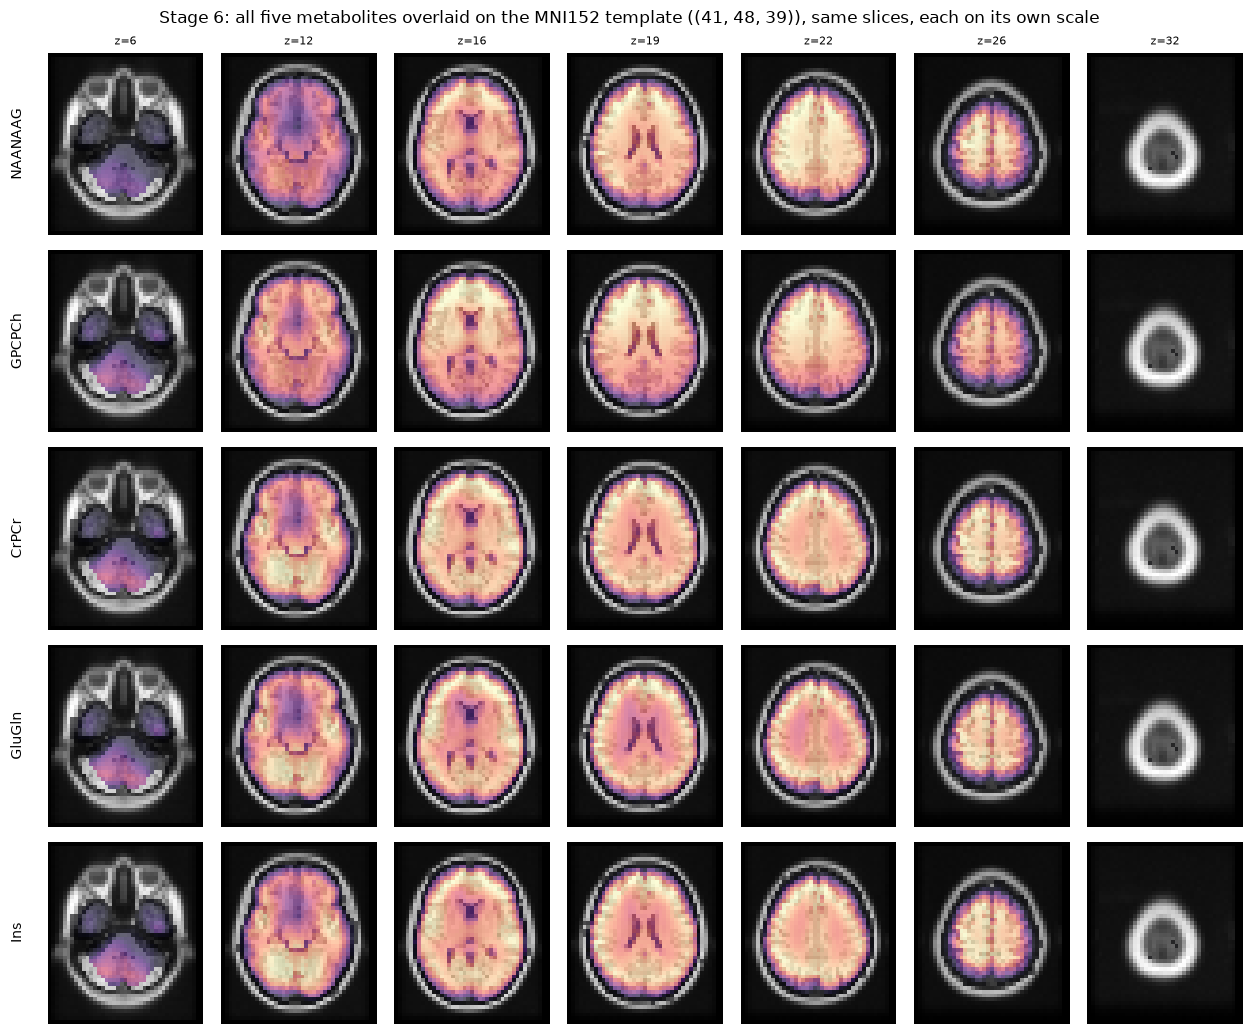

In [11]:
from nilearn.image import resample_to_img

mni_signal_paths = {
    met: PRECOMPUTED / "mrsi" / "mni" / f"sub-{SUBJECT}_ses-{SESSION}_space-MNI152NLin2009cAsym_res-5_met-{met}_desc-signal_mrsi.nii.gz"
    for met in METABOLITES
}
mni_signal = {met: load_canonical_data(p) for met, p in mni_signal_paths.items()}

# The MNI template (template_img, loaded in Stage 0b) resampled onto this
# metabolite map's own 5mm grid -- not just the same resolution, the exact
# same affine/shape -- so it overlays pixel-for-pixel as the alignment-check
# background, the same role raw_t1w played for Stage 3's T1w-space check.
template_resampled_img = resample_to_img(template_img, nib.load(str(mni_signal_paths[MET])), interpolation="continuous")
template_resampled = np.asarray(nib.as_closest_canonical(template_resampled_img).get_fdata())

# Slice indices chosen once from the reference metabolite's own coverage,
# then reused for every metabolite's panel so the same column always means
# the same anatomical location across the row.
mni_slice_indices = [index for index, _ in axial_slices_center_weighted(mni_signal[MET], 10)]

fig, axes = plt.subplots(len(METABOLITES), len(mni_slice_indices), figsize=(1.8 * len(mni_slice_indices), 2.1 * len(METABOLITES)))
for row, met in enumerate(METABOLITES):
    vmax_met = float(np.percentile(mni_signal[met][mni_signal[met] > 0], 99)) if np.any(mni_signal[met] > 0) else None
    for col, index in enumerate(mni_slice_indices):
        axes[row, col].imshow(mid_axial(template_resampled, index), cmap="gray")
        overlay_plane = mid_axial(mni_signal[met], index)
        masked = np.ma.masked_where(overlay_plane <= 0, overlay_plane)
        axes[row, col].imshow(masked, cmap="magma", alpha=0.6, vmax=vmax_met)
        axes[row, col].axis("off")
        if row == 0:
            axes[row, col].set_title(f"z={index}", fontsize=8)
    axes[row, 0].text(-0.15, 0.5, met, transform=axes[row, 0].transAxes, ha="right", va="center", fontsize=10, rotation=90)
fig.suptitle(f"Stage 6: all five metabolites overlaid on the MNI152 template ({mni_signal[MET].shape}), same slices, each on its own scale")
plt.tight_layout()
plt.show()

## Stage 7 — Metabolic connectivity (live)

This subject was processed without `--parcellation-mode chimera` (which requires FreeSurfer `recon-all` and `FS_LICENSE`), so this stage instead uses `--parcellation-mode atlas --atlas chimera-LFMIHIFIS_scale3`: a pre-bundled, already-computed MNI-space atlas sharing Chimera's labeling scheme (cortex=L/Lausanne, subcortex=F/FreeSurfer-aseg, etc.) that is *warped into subject space* via the registration transforms already computed above, rather than fusing several atlases live via the full Chimera tool. Both ultimately produce a `ParcellationResult` the rest of the pipeline treats identically; `atlas` mode is the lighter-weight path when a bundled scheme already covers what's needed.

1. `mrsiprep.parcellation.mni_atlas.run_mni_parcellation` projects the bundled MNI atlas through MNI→T1w→MRSI (reusing Stage 3's live registration transform for the T1w→MRSI leg, and this subject's precomputed T1w→MNI transform for the MNI→T1w leg).
2. `mrsiprep.connectivity.connectivity.compute_metabolite_connectivity` builds the regional metabolic profiles (with CRLB-based Monte Carlo uncertainty propagation, `n_perturbations=50`) and their pairwise Spearman similarity matrix, using all 5 metabolites' PVC-corrected maps (CrPCr's is Stage 4's live-computed PVC output; the other four reuse this subject's precomputed PVC outputs, since Stage 4 above only reruns PVC for the single reference metabolite). The LFM atlas's 654 parcels are far too many for a legible native-MRSI-grid matrix at this coarse acquisition resolution (many parcels fall on only 1-2 voxels after resampling), so this cell keeps only parcels with at least 5 MRSI voxels of coverage.

In [12]:
from mrsiprep.registration.transforms import ants_transform_prefix, transform_paths
from mrsiprep.parcellation.mni_atlas import run_mni_parcellation

# T1w-to-MNI: this subject's precomputed transform (not re-run live; see
# Stage 6's note -- it's a per-dataset, backend-independent-of-Stage-3 run).
precomputed_anat_prefix = ants_transform_prefix(DATASET_ROOT / "derivatives" / "mrsiprep", SUBJECT, SESSION, "anat", backend="ants")
mni_to_t1 = transform_paths(precomputed_anat_prefix, direction="inverse", backend="ants")

# T1w-to-MRSI: the inverse of Stage 3's own live registration, when it ran live.
if reg_result is not None:
    t1_to_mrsi = reg_result.inverse
else:
    precomputed_mrsi_prefix = ants_transform_prefix(DATASET_ROOT / "derivatives" / "mrsiprep", SUBJECT, SESSION, "mrsi", backend="ants")
    t1_to_mrsi = transform_paths(precomputed_mrsi_prefix, direction="inverse", backend="ants")

atlas_parcels = run_mni_parcellation(config, SUBJECT, SESSION, mrsi_ref_path, t1w_brain_path, mni_to_t1, t1_to_mrsi)[0]
print(f"Projected atlas: {atlas_parcels.atlas_name}, MRSI-space labels at {atlas_parcels.atlas_mrsi}")

atlas_mrsi_data = load_canonical_data(atlas_parcels.atlas_mrsi).astype(int)
ids, counts = np.unique(atlas_mrsi_data[atlas_mrsi_data > 0], return_counts=True)
well_covered_parcel_ids = sorted(int(i) for i, c in zip(ids, counts) if c >= 5)
print(f"{len(well_covered_parcel_ids)} of {len(ids)} parcels have >=5 MRSI voxels of coverage; using those.")

Projected atlas: chimeraLFMIHIFIS_scale3, MRSI-space labels at /tmp/mrsiprep_walkthrough_kx35my4z/mrsiprep/sub-01/ses-01/anat/synthseg/sub-01_ses-01_space-mrsi_atlas-chimeraLFMIHIFIS_scale3_dseg.nii.gz
347 of 653 parcels have >=5 MRSI voxels of coverage; using those.


Output()

Connectivity matrix: (347, 347), method=spearman


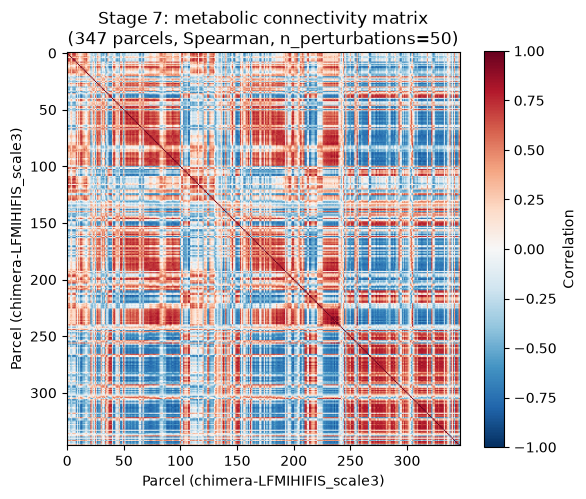

In [13]:
from mrsiprep.connectivity.connectivity import compute_metabolite_connectivity

# All 5 metabolites' PVC-corrected maps: CrPCr from Stage 4's live result,
# the rest from this subject's precomputed PVC outputs (Stage 4 above only
# reruns PVC for the single reference metabolite).
connectivity_metabolite_maps = {}
for met in METABOLITES:
    if met == MET:
        connectivity_metabolite_maps[met] = pvc_map_for_profiles
    else:
        connectivity_metabolite_maps[met] = PRECOMPUTED / "mrsi" / "orig-pvc" / f"sub-{SUBJECT}_ses-{SESSION}_space-mrsi_met-{met}_desc-signalpvc_mrsi.nii.gz"

connectivity_result = compute_metabolite_connectivity(
    connectivity_metabolite_maps,
    raw_mrsi_crlb_paths,
    brainmask_path,
    atlas_parcels.atlas_mrsi,
    well_covered_parcel_ids,
    method="spearman",
    n_perturbations=50,
    seed=0,
)
print(f"Connectivity matrix: {connectivity_result.similarity.shape}, method={connectivity_result.method}")

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(connectivity_result.similarity, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xlabel("Parcel (chimera-LFMIHIFIS_scale3)")
ax.set_ylabel("Parcel (chimera-LFMIHIFIS_scale3)")
ax.set_title(f"Stage 7: metabolic connectivity matrix\n({len(well_covered_parcel_ids)} parcels, Spearman, n_perturbations=50)")
fig.colorbar(im, ax=ax, label="Correlation")
plt.tight_layout()
plt.show()

## Stage 8 — Generating the HTML QC report (live)

Every MRSIPrep run ends with an automated, tabbed HTML report (registration overlays, voxelwise/regional QC tables, spike-filter comparisons, and more) — `mrsiprep.reports.html.generate_subject_report`. This cell merges this notebook's own live-computed outputs (spike-filtered/PVC-corrected maps, the live registration transform, the live-projected LFM atlas) with the rest of this subject's already-computed derivatives it didn't recompute (SynthSeg segmentation, MNI resampling), by symlinking the missing pieces into the same scratch directory, then calls the real report generator on the merged tree.

**To view it:** download `report_path` below (printed at the end of this cell) and open it in a browser. It will not render correctly if viewed through GitHub's online notebook viewer or a raw-file URL — GitHub does not serve the report's sibling image/CSS assets, so most of it will appear broken. Open the downloaded `.html` file locally instead.

In [14]:
from mrsiprep.reports.html import generate_subject_report

scratch_recording_dir = SCRATCH_DIR / "mrsiprep" / f"sub-{SUBJECT}" / f"ses-{SESSION}"

# Symlink individual precomputed files this notebook didn't recompute live
# (SynthSeg outputs, MNI-space maps, and -- for whichever of the 5
# metabolites' confound/QC files Stage 1/4/5 above didn't write live --
# their precomputed equivalents) into the scratch tree the report reads
# from, without overwriting anything already written live.
def merge_precomputed(relative_dir: str) -> None:
    source_dir = PRECOMPUTED / relative_dir
    dest_dir = scratch_recording_dir / relative_dir
    if not source_dir.is_dir():
        return
    dest_dir.mkdir(parents=True, exist_ok=True)
    for source_file in source_dir.rglob("*"):
        if source_file.is_dir():
            continue
        rel = source_file.relative_to(source_dir)
        dest_file = dest_dir / rel
        if dest_file.exists() or dest_file.is_symlink():
            continue
        dest_file.parent.mkdir(parents=True, exist_ok=True)
        dest_file.symlink_to(source_file.resolve())

for relative_dir in ("anat", "mrsi/mni", "confounds", "logs"):
    merge_precomputed(relative_dir)

report_path = generate_subject_report(config, SUBJECT, SESSION, outputs={})
print(f"Report written to: {report_path}")
print("Download this file (and its sibling 'figures/' folder, if present) and open it in a browser.")

Report written to: /tmp/mrsiprep_walkthrough_kx35my4z/mrsiprep/sub-01/ses-01/reports/sub-01_ses-01_desc-report.html
Download this file (and its sibling 'figures/' folder, if present) and open it in a browser.


## Cleanup

In [15]:
import shutil as _shutil

_shutil.rmtree(SCRATCH_DIR, ignore_errors=True)
print(f"Removed scratch directory: {SCRATCH_DIR}")

Removed scratch directory: /tmp/mrsiprep_walkthrough_kx35my4z


## Beyond this notebook

This notebook used `--parcellation-mode atlas` (a pre-bundled MNI-space atlas) rather than `--parcellation-mode chimera` (live multi-atlas fusion via the Chimera tool, requiring FreeSurfer `recon-all` and `FS_LICENSE`) for the connectivity stage — both are real, supported options; `chimera` produces its own subject-specific parcellation rather than reusing a bundled one, at the cost of a FreeSurfer dependency and substantially longer runtime.

See the [CLI reference](https://mrsiprep.readthedocs.io) for the full set of flags, and the MRSIPrep manuscript's Methods section for the full per-stage detail behind everything shown above.